# Pneumodetect — demo application (N3)

**Authors:** Asulkhan Aidarkhanov, Ravil Serikuly · **Group:** BDA-2401
**Course:** Machine Learning Algorithms, Astana IT University · **Instructor:** Assiya Karatay

## README

This notebook is the user-facing part of Pneumodetect. It **does not retrain anything**: it loads the two models
saved by the main notebook `Pneumodetect.ipynb` (N8) and wraps them into a small web interface built with
[Gradio](https://www.gradio.app). The user uploads a frontal chest X-ray and gets

* the probability of pneumonia (binary ResNet50 model, sigmoid output — D5);
* the likely type, bacterial or viral (3-class model — N1);
* a **"low confidence — manual review recommended"** flag when 0.40 ≤ P(pneumonia) ≤ 0.60 (N7);
* a Grad-CAM heat map showing which region influenced the prediction (N2).

Pneumodetect is a course project, **not a medical device**; its output is not a diagnosis.

### How to run

**Kaggle (recommended).** Open this notebook on Kaggle, *Add Input* → the output of the notebook
`keonmei/pneumodetect` (the two `.keras` files) and the dataset `paultimothymooney/chest-xray-pneumonia`
(example images). *Settings*: Accelerator **GPU T4**, Internet **On**. *Run All* — the last cell prints a public
`https://….gradio.live` link that stays open while the session runs.

**Google Colab.** Add the secret `KAGGLE_API_TOKEN` (or `KAGGLE_USERNAME` + `KAGGLE_KEY`), choose a T4 GPU and
*Run all*: the models are downloaded from the Kaggle notebook output through the Kaggle API.

### Structure

1. Setup and GPU check
2. Loading the trained models (N8)
3. Prediction pipeline: the same preprocessing as in training, Grad-CAM, report text
4. Examples on held-out test X-rays (the I/O examples of the proposal, section 1.2) and prediction time
5. Web interface (N3)

## 1. Setup and GPU check

In [1]:
import subprocess, sys

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "gradio", "kagglehub>=0.3.4", "kaggle>=1.7.4"],
               check=False)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', '-U', 'gradio', 'kagglehub>=0.3.4', 'kaggle>=1.7.4'], returncode=0)

In [2]:
import json, os, time
from pathlib import Path

import gradio as gr
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from PIL import Image

tf.get_logger().setLevel("ERROR")
print("TensorFlow:", tf.__version__, "| Gradio:", gr.__version__)

IMG_SIZE = 224                       # D2: the models were trained on 224x224 inputs
UNCERTAIN = (0.40, 0.60)             # N7: probabilities in this band are flagged for manual review
DECISION_THRESHOLD = 0.5             # default decision rule of the sigmoid output
CLASSES3 = ["normal", "bacterial", "viral"]
TRAINING_NOTEBOOK = "keonmei/pneumodetect"
KERMANY_HANDLE = "paultimothymooney/chest-xray-pneumonia"
SEED = 42

IN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ
IN_BATCH = os.environ.get("KAGGLE_KERNEL_RUN_TYPE") == "Batch"     # "Save & Run All" on Kaggle: nobody to click
try:
    import google.colab  # noqa: F401  (Kaggle images ship this package too, so Kaggle is checked first)
    IN_COLAB = not IN_KAGGLE
except ImportError:
    IN_COLAB = False
WORK_DIR = Path("/kaggle/working") if IN_KAGGLE else Path("/content") if IN_COLAB else Path.cwd()

gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
print("Platform:", "Kaggle" if IN_KAGGLE else "Colab" if IN_COLAB else "local", "| GPUs:", gpus)

I0000 00:00:1794761191.212720      16 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794761207.440511      16 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow: 2.21.0 | Gradio: 6.32.0
Platform: Kaggle | GPUs: []


E0000 00:00:1794761212.556619      16 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## 2. Loading the trained models (N8)

The main notebook saved the best checkpoints as `.keras` files. On Kaggle they are attached as the input
`keonmei/pneumodetect`; elsewhere they are downloaded once through the Kaggle API.

In [3]:
MODEL_FILES = ["pneumodetect_resnet50_best.keras", "pneumodetect_resnet50_3class_best.keras"]


def setup_kaggle_credentials():
    if IN_KAGGLE or os.environ.get("KAGGLE_API_TOKEN") or (Path.home() / ".kaggle").exists():
        return
    if IN_COLAB:
        from google.colab import userdata

        def secret(name):
            try:
                return userdata.get(name)
            except Exception:
                return None
        if secret("KAGGLE_API_TOKEN"):
            os.environ["KAGGLE_API_TOKEN"] = secret("KAGGLE_API_TOKEN")
        elif secret("KAGGLE_USERNAME") and secret("KAGGLE_KEY"):
            os.environ["KAGGLE_USERNAME"], os.environ["KAGGLE_KEY"] = secret("KAGGLE_USERNAME"), secret("KAGGLE_KEY")


def find_models():
    found = {}
    for root in (Path("/kaggle/input"), WORK_DIR / "models"):
        if root.exists():
            for name in MODEL_FILES:
                hits = sorted(root.rglob(name))
                if hits and name not in found:
                    found[name] = hits[0]
    return found


paths = find_models()
if len(paths) < len(MODEL_FILES):
    setup_kaggle_credentials()
    (WORK_DIR / "models").mkdir(exist_ok=True)
    print("Downloading the trained models from the Kaggle notebook output...")
    subprocess.run(["kaggle", "kernels", "output", TRAINING_NOTEBOOK, "-p", str(WORK_DIR / "models")], check=True)
    paths = find_models()

t0 = time.time()
BINARY = tf.keras.models.load_model(paths[MODEL_FILES[0]])
MODEL3 = tf.keras.models.load_model(paths[MODEL_FILES[1]])
for name, p in paths.items():
    print(f"{name}: {p.stat().st_size / 1e6:.0f} MB")
print(f"Both models loaded in {time.time() - t0:.1f} s, no retraining.")

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 46 variables whereas the saved optimizer has 50 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


pneumodetect_resnet50_best.keras: 334 MB
pneumodetect_resnet50_3class_best.keras: 334 MB
Both models loaded in 7.9 s, no retraining.


## 3. Prediction pipeline

The uploaded image goes through **exactly the training preprocessing**: grayscale, bilinear resize to 224×224,
then three identical channels with values 0–255 (the ImageNet normalisation is a layer inside the model).
Grad-CAM is the same implementation as in section 11 of the main notebook: gradients of the class logit with
respect to the last convolutional block, evaluated in float32.

In [4]:
def preprocess(image):
    # Any PIL image / numpy array -> (224x224 uint8 grayscale for display, float32 model input of shape (1,224,224,3)).
    if isinstance(image, np.ndarray):
        image = Image.fromarray(image)
    gray = image.convert("L").resize((IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR, reducing_gap=2.0)
    gray = np.asarray(gray, dtype=np.uint8)
    return gray, np.repeat(gray[None, ..., None], 3, axis=-1).astype(np.float32)


def split_model(model):
    # input -> augmentation -> preprocessing -> backbone -> head; returns (before, backbone, head).
    base = next(l for l in model.layers if isinstance(l, tf.keras.Model) and l.name != "augmentation")
    i = model.layers.index(base)
    before = [l for l in model.layers[1:i] if l.name != "augmentation"]      # augmentation is off at inference
    return before, base, model.layers[i + 1:]


def grad_cam(model, images, class_index=None):
    # images: float32 (n, 224, 224, 3) in 0..255. Returns heat maps (n, 224, 224) in 0..1 and model outputs.
    before, base, head = split_model(model)
    assert [type(l).__name__ for l in head] == ["GlobalAveragePooling2D", "Dropout", "Dense"], head
    dense = head[-1]
    kernel, bias = tf.cast(dense.kernel, tf.float32), tf.cast(dense.bias, tf.float32)
    x = tf.convert_to_tensor(images, tf.float32)
    for layer in before:
        x = layer(x, training=False)
    fmap = tf.cast(base(x, training=False), tf.float32)
    with tf.GradientTape() as tape:
        tape.watch(fmap)
        logits = tf.matmul(tf.reduce_mean(fmap, axis=(1, 2)), kernel) + bias
        if logits.shape[-1] == 1:
            target, out = logits[:, 0], tf.sigmoid(logits)
        else:
            idx = tf.argmax(logits, axis=-1) if class_index is None else tf.fill([tf.shape(logits)[0]], class_index)
            target, out = tf.gather(logits, idx, axis=1, batch_dims=1), tf.nn.softmax(logits)
    grads = tape.gradient(target, fmap)
    weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(weights * fmap, axis=-1))
    cam = cam / (tf.reduce_max(cam, axis=(1, 2), keepdims=True) + 1e-8)
    cam = tf.image.resize(cam[..., None], (IMG_SIZE, IMG_SIZE), method="bilinear")[..., 0]
    return cam.numpy(), out.numpy()


def overlay(gray, cam, alpha=0.35):
    # Grayscale X-ray + jet-coloured heat map -> RGB uint8 image.
    heat = plt.get_cmap("jet")(cam)[..., :3]
    base = np.repeat(gray[..., None] / 255.0, 3, axis=-1)
    return np.clip(255 * ((1 - alpha) * base + alpha * heat), 0, 255).astype(np.uint8)


def analyse(image):
    gray, x = preprocess(image)
    cam, out = grad_cam(BINARY, x)
    p = float(out[0, 0])                                    # P(pneumonia) from the binary model
    probs3 = MODEL3(x, training=False).numpy()[0].astype(float)
    bacterial = probs3[1] / (probs3[1] + probs3[2])         # type, given that it is pneumonia
    return {"p": p, "bacterial": bacterial, "viral": 1 - bacterial, "gray": gray, "cam": cam[0]}


def report(r):
    # Text in the format of the proposal's I/O examples (section 1.2).
    p = r["p"]
    text = f"Pneumonia: {100 * p:.1f}% / Normal: {100 * (1 - p):.1f}%."
    if p >= DECISION_THRESHOLD:
        text += f" Predicted type: Bacterial ({100 * r['bacterial']:.0f}%), Viral ({100 * r['viral']:.0f}%)."
    if UNCERTAIN[0] <= p <= UNCERTAIN[1]:
        text += " Low confidence – manual review recommended."
    elif p < DECISION_THRESHOLD:
        text += " No pneumonia detected."
    return text


def predict(image):
    # Gradio callback: image -> (probabilities for gr.Label, report text, Grad-CAM overlay).
    if image is None:
        return None, "Upload a frontal chest X-ray.", None
    r = analyse(image)
    return {"Pneumonia": r["p"], "Normal": 1 - r["p"]}, report(r), overlay(r["gray"], r["cam"])

## 4. Examples on held-out test X-rays

The examples come from the official Kermany **test** folder, which the models never saw during training.
We show one **randomly drawn** bacterial, viral and normal case (not hand-picked, so errors can appear), plus
the test image whose probability is closest to 0.5 (the "uncertain" example of the proposal), and measure the
time needed for one complete prediction (both models + Grad-CAM + report).

Kermany test images: 624


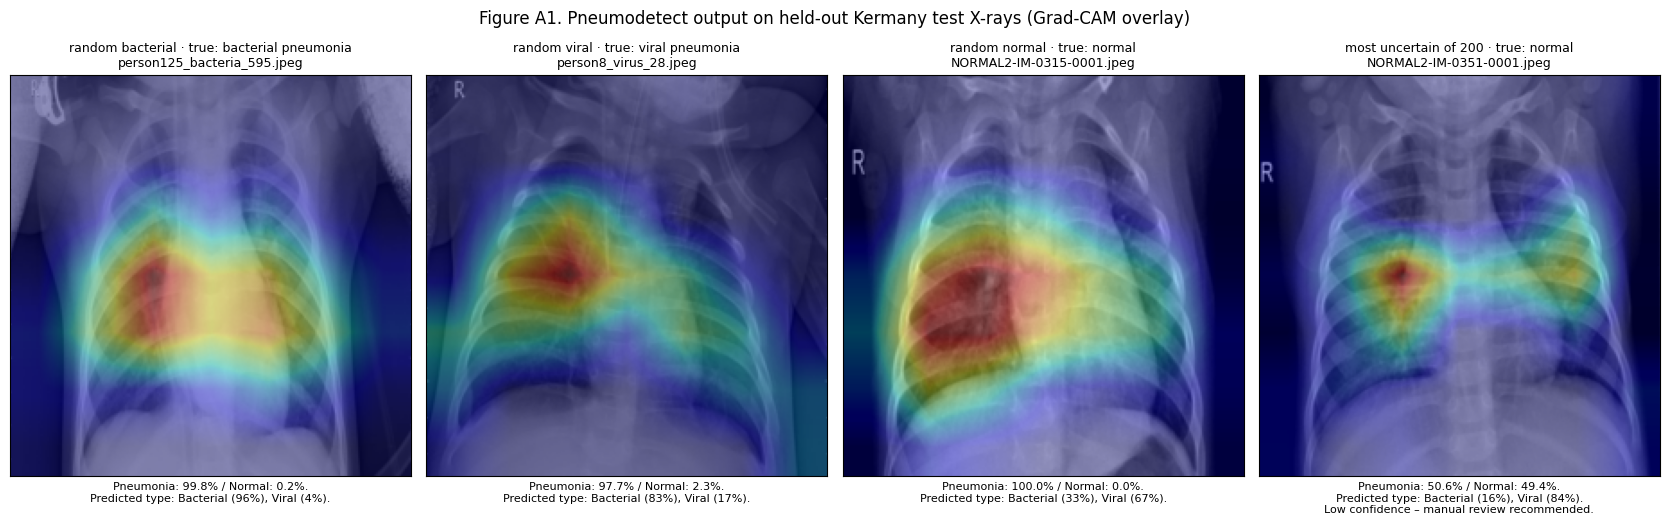

[random bacterial | true: bacterial pneumonia] person125_bacteria_595.jpeg
  -> Pneumonia: 99.8% / Normal: 0.2%. Predicted type: Bacterial (96%), Viral (4%).
[random viral | true: viral pneumonia] person8_virus_28.jpeg
  -> Pneumonia: 97.7% / Normal: 2.3%. Predicted type: Bacterial (83%), Viral (17%).
[random normal | true: normal] NORMAL2-IM-0315-0001.jpeg
  -> Pneumonia: 100.0% / Normal: 0.0%. Predicted type: Bacterial (33%), Viral (67%).
[most uncertain of 200 | true: normal] NORMAL2-IM-0351-0001.jpeg
  -> Pneumonia: 50.6% / Normal: 49.4%. Predicted type: Bacterial (16%), Viral (84%). Low confidence – manual review recommended.

Prediction time for one image (both models + Grad-CAM + report), median of 10: 0.92 s -> target < 2 s: met


In [5]:
kermany_root = Path(kagglehub.dataset_download(KERMANY_HANDLE))
test_files, seen = [], set()
for f in sorted(kermany_root.rglob("*.jpeg")):
    parts = f.parts
    if "__MACOSX" in parts or "test" not in parts:
        continue
    cls = "NORMAL" if "NORMAL" in parts else "PNEUMONIA"
    if (cls, f.name) not in seen:                        # the Kaggle archive contains a duplicate copy
        seen.add((cls, f.name))
        test_files.append(f)
print("Kermany test images:", len(test_files))

rng = np.random.default_rng(SEED)
pick = lambda files: files[rng.integers(len(files))]
bacterial = [f for f in test_files if "bacteria" in f.name]
viral = [f for f in test_files if "virus" in f.name]
normal = [f for f in test_files if "NORMAL" in f.parts]

# The most uncertain image among 200 random test X-rays (binary model only, batched).
pool = [test_files[i] for i in rng.choice(len(test_files), size=min(200, len(test_files)), replace=False)]
pool_x = np.concatenate([preprocess(Image.open(f))[1] for f in pool])
pool_p = BINARY.predict(pool_x, batch_size=32, verbose=0).ravel()
uncertain = pool[int(np.argmin(np.abs(pool_p - 0.5)))]

EXAMPLES = {"random bacterial": pick(bacterial), "random viral": pick(viral),
            "random normal": pick(normal), "most uncertain of 200": uncertain}


def true_label(f):
    return "normal" if "NORMAL" in f.parts else "bacterial pneumonia" if "bacteria" in f.name else "viral pneumonia"

predict(Image.open(EXAMPLES["random normal"]))                  # warm-up (graph tracing)
fig, axes = plt.subplots(1, len(EXAMPLES), figsize=(4.2 * len(EXAMPLES), 5.2))
rows = []
for ax, (kind, f) in zip(axes, EXAMPLES.items()):
    r = analyse(Image.open(f))
    ax.imshow(overlay(r["gray"], r["cam"]))
    ax.set_title(f"{kind} · true: {true_label(f)}\n{f.name}", fontsize=9)
    ax.set_xlabel(report(r).replace(". ", ".\n"), fontsize=8)
    ax.set_xticks([])
    ax.set_yticks([])
    rows.append({"example": kind, "true": true_label(f), "file": f.name, "output": report(r)})
fig.suptitle("Figure A1. Pneumodetect output on held-out Kermany test X-rays (Grad-CAM overlay)")
plt.tight_layout()
plt.savefig(WORK_DIR / "app_examples.png", dpi=120)
plt.show()

for row in rows:
    print(f"[{row['example']} | true: {row['true']}] {row['file']}\n  -> {row['output']}")

image = Image.open(EXAMPLES["random bacterial"])
times = []
for _ in range(10):
    t0 = time.perf_counter()
    predict(image)
    times.append(time.perf_counter() - t0)
latency = float(np.median(times))
print(f"\nPrediction time for one image (both models + Grad-CAM + report), median of 10: {latency:.2f} s "
      f"-> target < 2 s: {'met' if latency < 2 else 'not met'}")
json.dump({"examples": rows, "latency_s": latency}, open(WORK_DIR / "app_examples.json", "w"), indent=1)

## 5. Web interface (N3)

`gr.Interface` turns `predict` into a web page: an upload field on the left, the probabilities, the report
text and the Grad-CAM overlay on the right; the four test images above are offered as one-click examples.
`share=True` creates a temporary public link, so the demo also opens on a phone or another computer.
On a non-interactive Kaggle run (*Save & Run All*) nobody can open the page, so the interface is built
but not launched.

In [6]:
import inspect
import shutil

# Gradio only serves files from the working directory, so the example X-rays are copied there first.
example_dir = WORK_DIR / "examples"
example_dir.mkdir(exist_ok=True)
example_paths = [str(shutil.copy(f, example_dir / f.name)) for f in EXAMPLES.values()]

options = {"flagging_mode": "never"} if "flagging_mode" in inspect.signature(gr.Interface).parameters else {}
demo = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil", label="Frontal chest X-ray (PA/AP), JPEG or PNG"),
    outputs=[gr.Label(num_top_classes=2, label="Probability"),
             gr.Textbox(label="Result"),
             gr.Image(label="Grad-CAM: regions that influenced the prediction")],
    examples=[[p] for p in example_paths],
    title="Pneumodetect — pneumonia detection from chest X-rays",
    description=("ResNet50 fine-tuned on ~108k chest X-rays (NIH ChestX-ray14 + RSNA labels + Kermany). "
                 "Probabilities between 40% and 60% are flagged for manual review. "
                 "Course project, not a medical device."),
    **options,
)

if IN_BATCH:
    print("Non-interactive Kaggle run: interface built, not launched. Open the notebook in the editor to launch it.")
else:
    demo.launch(share=True, debug=False)

Non-interactive Kaggle run: interface built, not launched. Open the notebook in the editor to launch it.
